# HCT116 overlap between 0 hrs and 6 hrs for MIA-Jet 

In [ ]:
import sys
sys.path.append('..')
from utils.plotting import plot_n_hic, genomic_labels

from func_analysis import *
from func_plotting import *
from func_iou import *
from func_pileup import *

import itertools
from matplotlib_venn import venn2

def safe_int(x):
    try:
        return int(x)
    except ValueError:
        return x

In [2]:
# Analysis parameters
output_name = "v2.0.3"
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_{output_name}"

# Pileup parameters
data_type = "oe"
expected_stack_size = 100

# Overlap parameters
iou_threshold = 0  # ANY overlap

exp_name_1 = "HCT116_RAD21-auxin-0hr_hic_Rao-2017_4DNFIP71EWXC_hg38"
exp_name_2 = "HCT116_RAD21-auxin-6hr_hic_Rao-2017_4DNFILIM6FDL_hg38"

hic_file_0hr = "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_RAD21-auxin-0hr_hic_Rao-2017_4DNFIP71EWXC_hg38.hic" # hg38
hic_file_6hr = "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_RAD21-auxin-6hr_hic_Rao-2017_4DNFILIM6FDL_hg38.hic" # hg38

data_name = "HCT116 RAD21 depletion"

resolution = 10000 # 10Kb resolution
normalization = "VC_SQRT"

# Overlap parameter is relative to resolution
buffer_radius = 3 * resolution

# MIA-JET
result_type_0hr = "q_val_0.5-0.95"
result_type_6hr = "q_val_0.5" # no compartment mode
# result_type_6hr = result_type_0hr  # compartment mode
f_pred_miajet_0hr_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_1}_chr_combined_{genomic_labels(resolution)}/{exp_name_1}_chr_combined_{result_type_0hr}_{genomic_labels(resolution)}_summary_table.csv"
f_pred_miajet_0hr_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_1}_chr_combined_{genomic_labels(resolution)}/{exp_name_1}_chr_combined_{result_type_0hr}_{genomic_labels(resolution)}_expanded_table.csv"

f_pred_miajet_6hr_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_2}_chr_combined_{genomic_labels(resolution)}/{exp_name_2}_chr_combined_{result_type_6hr}_{genomic_labels(resolution)}_summary_table.csv"
f_pred_miajet_6hr_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_2}_chr_combined_{genomic_labels(resolution)}/{exp_name_2}_chr_combined_{result_type_6hr}_{genomic_labels(resolution)}_expanded_table.csv"

names = [
    "0hr",
    "6hr",
]

genomes = [
    "hg38",
    "hg38"
]

miajet_table_list = [
    f_pred_miajet_0hr_summary,
    f_pred_miajet_6hr_summary,
]

miajet_position_list = [
    f_pred_miajet_0hr_expanded,
    f_pred_miajet_6hr_expanded,
]

In [3]:
# Load MIA-Jet calls
selected_method = f"MIA-Jet {result_type_0hr}|{result_type_6hr}"
data_name += f" ({selected_method})"

tables = []
positions = []

for i in range(len(names)):
    miajet_positions = pd.read_csv(miajet_position_list[i], comment="#")
    miajet_table = pd.read_csv(miajet_table_list[i], comment="#")

    tables.append(miajet_table)
    positions.append(miajet_positions)

In [4]:
# Establish the common chromosomes between the 0hr and 6hr
common_chroms = []
for t in tables:
    common_chroms += t["chrom"].unique().tolist()

common_chroms = set(list(common_chroms))

In [5]:
# We make a new object for proper Hi-C read-in
hic_file = [hic_file_0hr, hic_file_6hr]
names_abbrev = ["0hr", "6hr"]

position_dict = dict(zip(names, positions))
table_dict = dict(zip(names, tables))

## Insulation boxplot: reference as 0hr

In [6]:
# Define insulation score data
chip_files = [
    '/nfs/turbo/umms-minjilab/downloaded_data/miajet_data_temp/HCT116_RAD21_AID_0hr_insituhic_insulation-score_plus_minus_4DNFIGKFF445.bigWig',
    '/nfs/turbo/umms-minjilab/downloaded_data/miajet_data_temp/HCT116_RAD21_AID_6hr_insituhic_insulation-score_plus_minus_4DNFIHLQB84S.bigWig',
]

chip_names_abrev = ["0hr", "6hr"]

f_chrom_sizes = "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"

In [7]:
window_plus_minus = resolution

bed_tables = []
for i, (s, e) in enumerate(zip(tables, positions)):
    bed_tables.append(generate_bed_3(s, e, project_midpoint_to_diag=True, eps=window_plus_minus)) # revision: use closest point to main diagonal as root

In [8]:
# Common bed dataframe i.e. 0hr locations
common_bed_df = bed_tables[0]
stat = "max"

# single interval set from the common locations
intervals = [common_bed_df[["unique_id", "chrom", "start", "end"]].copy().reset_index(drop=True)]

In [9]:
# both ChIP tracks evaluated at the SAME common locations
chipseq_values = extract_chipseq_values(chip_files, intervals, f_chrom_sizes, common_chroms, names, stat=stat)

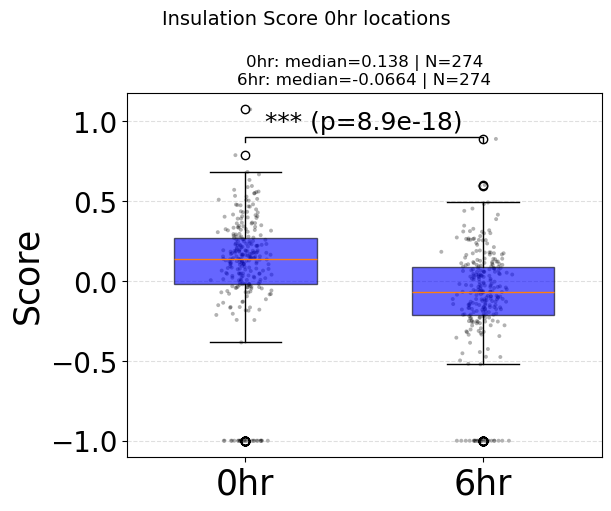

In [10]:
# one array per track (0hr, 6hr) at the common locations -> interval index is fixed at 0
obs_values = [np.asarray(list(chipseq_values[c][0].values())) for c in range(len(chip_files))]

# colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
fig, ax = plt.subplots(1, 1, figsize=(6, 5), sharey=True, layout="constrained")

data_pair = []
for raw_vals in obs_values:
    vals = raw_vals[~np.isnan(raw_vals)]
    # vals = np.clip(vals, 0, None)
    # vals = np.log10(vals + 1)
    data_pair.append(vals)

positions_x = np.arange(1, len(data_pair) + 1)
add_pairwise_sig(ax, positions_x, data_pair, fontsize=18, pad_from_max=-0.31)
bp = ax.boxplot(data_pair, patch_artist=True, widths=0.6)
for i in range(len(data_pair)):
    bp['boxes'][i].set_facecolor('blue')
    bp['boxes'][i].set_alpha(0.6)
for pos, vals in zip(positions_x, data_pair):
    x = np.full_like(vals, pos, dtype=float) + np.random.normal(0, 0.05, len(vals))
    ax.scatter(x, vals, s=8, alpha=0.3, color='k', edgecolor='none')

ax.set_xticks(positions_x)
ax.set_xticklabels(chip_names_abrev, rotation=0, ha="center")   # <-- 0hr vs 6hr
title_boxstat = title_boxplot("", chip_names_abrev, data_pair)
ax.set_title(title_boxstat)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_ylabel("Score", fontsize=25)

ax.tick_params(axis='y', labelsize=20)
ax.tick_params(axis='x', labelsize=25)

fig.suptitle(f"Insulation Score {names[0]} locations", fontsize=14)

# plt.savefig(f"{save_path}/{data_name}_reference0hr_insulation_boxplot-{data_type}.png", dpi=300, bbox_inches='tight')

plt.show()

# For Agg and below

In [11]:
# Use the agg bed_table accumulation method
bed_tables = []
for i, (s, e) in enumerate(zip(tables, positions)):
    bed_tables.append(generate_bed_2(s, e, eps=500e3, fraction=1.5))

## Agg: reference as 0 hr

In [12]:
chrom_sizes = bf.fetch_chromsizes(genomes[0], as_bed=True)

# Common bed dataframe i.e. 0hr locations
common_bed_df = bed_tables[0]

In [13]:
# PLOT REFERENCE OF 0HR
agg_map = []
vmaxes = []
df_stack = []

for idx in range(len(bed_tables)):
    # Get pileups for each bed_df
    s, d, r = get_pileups_dynamic_resolution(
        hic_file=hic_file[idx],
        bed_df_in=common_bed_df,
        expected_stack_size=expected_stack_size,
        chrom_sizes=chrom_sizes,
        chromosomes='all',
        window_range=(None, None),
        data_type=data_type,
        normalization=normalization,
        sort=True,
        verbose=True
    )

    # Remove centromeres and resize square stacks
    s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

    if data_type == "observed":
        s = np.log10(s + 1) # log transform for visualization

    a = np.mean(s, axis=0)
    vmaxes.append(np.percentile(a, 99))  # store the 99th percentile for color scaling
    agg_map.append(a)  # average over all stacks
    df_stack.append(d)  # store the DataFrame for later use

Retrieving pileups: 100%|██████████| 274/274 [00:12<00:00, 21.40it/s]


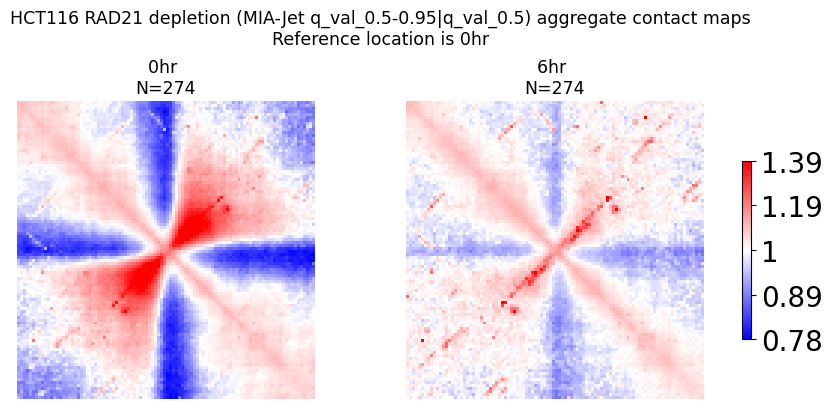

In [14]:
titles = [f"{names[i]} \nN={len(df_stack[i])}" for i in range(len(names))]

plot_n_hic(
    agg_map,
    suptitle=f"{data_name} aggregate contact maps\nReference location is 0hr",
    resolution=None,
    cmap_label=None,
    titles=titles,
    cmap='bwr',
    vcenter=1,
    standardize_cbar=True,
    show=True, 
    vmax=vmaxes,
    ppr=4,
    # savepath=f"{save_path}/{data_name}_reference0hr_agg_map-{data_type}.png",
    cbar_fontsize=20,
    hide_axis=True,
)

## Agg all called

In [15]:
# PLOT ALL CALLED
agg_map = []
vmaxes = []
df_stack = []

for idx, bed_df in enumerate(bed_tables):
    # Get pileups for each bed_df
    s, d, r = get_pileups_dynamic_resolution(
        hic_file=hic_file[idx],
        bed_df_in=bed_df,
        expected_stack_size=expected_stack_size,
        chrom_sizes=chrom_sizes,
        chromosomes='all',
        window_range=(None, None),
        data_type=data_type,
        normalization=normalization,
        sort=True,
        verbose=True
    )

    # Remove centromeres and resize square stacks
    s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

    if data_type == "observed":
        s = np.log10(s + 1) # log transform for visualization

    a = np.mean(s, axis=0)
    vmaxes.append(np.percentile(a, 99))  # store the 99th percentile for color scaling
    agg_map.append(a)  # average over all stacks
    df_stack.append(d)  # store the DataFrame for later use

Retrieving pileups:   0%|          | 0/274 [00:00<?, ?it/s]

Retrieving pileups: 100%|██████████| 137/137 [00:05<00:00, 25.50it/s]


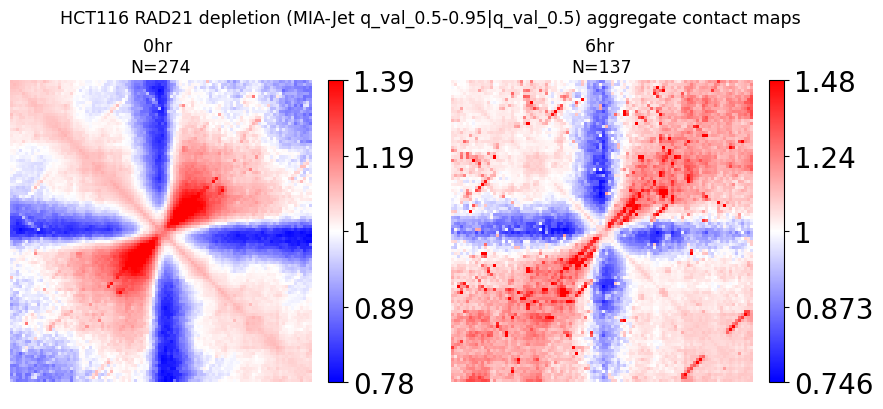

In [16]:
titles = [f"{names[i]} \nN={len(df_stack[i])}" for i in range(len(names))]

plot_n_hic(
    agg_map,
    suptitle=f"{data_name} aggregate contact maps",
    resolution=None,
    cmap_label=None,
    titles=titles,
    cmap='bwr',
    vcenter=1,
    standardize_cbar=False, # One modification to notebook
    show=True, 
    vmax=vmaxes,
    ppr=4,
    # savepath=f"{save_path}/{data_name}_all_agg_map-{data_type}.png",
    cbar_fontsize=20,
    hide_axis=True,
)

## Intersection

In [17]:
# COMPUTE OVERLAPS
results = pd.DataFrame(index=names, columns=names, dtype=int).fillna(0)
unique_identifiers = []
name_pairs = []
# fill main diagonal with the total number of jets from each method
for n in names:
    results.loc[n, n] = len(table_dict[n])

for n1, n2 in itertools.combinations(names, 2):

    print("-" * 20)
    print(f"Comparing {n1} and {n2}...")

    genome_wide_overlap = 0
    identifiers = []

    for chrom in common_chroms:

        # IOU method is per-chromosome so filter each table by chromosome
        t1 = position_dict[n1].loc[position_dict[n1]["chrom"] == chrom]
        t2 = position_dict[n2].loc[position_dict[n2]["chrom"] == chrom]

        if t1.empty or t2.empty:
            # if any of the two tables are empty then no need to check for overlaps.. there is none
            continue

        # Compute the pairs of jets in each direction
        pairs12 = match_by_iou(t1, t2, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")
        pairs21 = match_by_iou(t2, t1, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")

        # Construct graph and find unique pairs
        pairs = unique_pairs(pairs12, pairs21, method="optimal")

        genome_wide_overlap += len(pairs)
        identifiers += pairs # extend the list

    # Update results table
    results.loc[n1, n2] = genome_wide_overlap
    results.loc[n2, n1] = genome_wide_overlap  # symmetric

    unique_identifiers.append(identifiers)
    name_pairs.append((n1, n2))

print("Genome-wide overlaps:")
print(results)

--------------------
Comparing 0hr and 6hr...
Genome-wide overlaps:
       0hr    6hr
0hr  274.0   27.0
6hr   27.0  137.0


In [18]:
# COLLECT AGG DATA
agg_map_pairs = [] # aggregate contact map data
for (n1, n2), pairs in zip(name_pairs, unique_identifiers):
    safe_convert = np.vectorize(safe_int)

    if len(pairs) == 0:
        uid1 = np.array([])
        uid2 = np.array([])
    else:
        uid1 = np.array(pairs)[:, 0]  # unique identifiers from n1
        uid2 = np.array(pairs)[:, 1]  # unique identifiers from n2

        uid1 = safe_convert(uid1)
        uid2 = safe_convert(uid2)

    # These will be used to merge to extract the relevant positions
    df_id = pd.DataFrame({"unique_id" : uid1,})
    df_id_alt = pd.DataFrame({"unique_id" : uid2,})
    # Summary dataframe
    df_A = table_dict[n1]
    df_B = table_dict[n2]
    # Expanded dataframe
    df_pos_A = position_dict[n1].copy()
    df_pos_B = position_dict[n2].copy()

    # Summary dataframes (if intersection, then n1 takes preference)
    df_intersection = df_A[df_A["unique_id"].isin(df_id["unique_id"])].reset_index(drop=True)
    df_diff_A = df_A[~df_A["unique_id"].isin(df_id["unique_id"])].reset_index(drop=True)
    df_diff_B = df_B[~df_B["unique_id"].isin(df_id_alt["unique_id"])].reset_index(drop=True)

    # Matching expanded (position) dataframes
    df_pos_intersection = df_pos_A[df_pos_A["unique_id"].isin(df_id["unique_id"])].reset_index(drop=True)
    df_pos_diff_A = df_pos_A[~df_pos_A["unique_id"].isin(df_id["unique_id"])].reset_index(drop=True)
    df_pos_diff_B = df_pos_B[~df_pos_B["unique_id"].isin(df_id_alt["unique_id"])].reset_index(drop=True)

    # Make bed files to get stacks
    bed_intersection = generate_bed_2(df_intersection, df_pos_intersection, eps=500e3, fraction=1.5)
    bed_diff_A = generate_bed_2(df_diff_A, df_pos_diff_A, eps=500e3, fraction=1.5)
    bed_diff_B = generate_bed_2(df_diff_B, df_pos_diff_B, eps=500e3, fraction=1.5)

    A_idx = names.index(n1)
    B_idx = names.index(n2)

    bed_frames = [bed_diff_A, bed_intersection, bed_diff_B]
    chrom_sizes_comparison = [bf.fetch_chromsizes(genomes[A_idx]), bf.fetch_chromsizes(genomes[A_idx]), bf.fetch_chromsizes(genomes[B_idx])]
    hic_file_comparison = [hic_file[A_idx], hic_file[A_idx], hic_file[B_idx]]

    agg_map = []
    for j, bed_df in enumerate(bed_frames):
        # Get pileups for each bed_df
        s, d, r = get_pileups_dynamic_resolution(
            hic_file=hic_file_comparison[j],
            bed_df_in=bed_df,
            expected_stack_size=expected_stack_size,
            chrom_sizes=chrom_sizes_comparison[j],
            chromosomes='all',
            window_range=(None, None),
            data_type=data_type,
            normalization=normalization,
            sort=True,
            verbose=True
        )

        # Remove centromeres and resize square stacks
        s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

        if data_type == "observed":
            s = np.log10(s + 1) # log transform for visualization

        agg_map.append(np.mean(s, axis=0))  # average over all stacks

    agg_map_pairs.append(agg_map)

agg_map_pairs = np.array(agg_map_pairs)

Retrieving pileups: 100%|██████████| 110/110 [00:04<00:00, 25.14it/s]


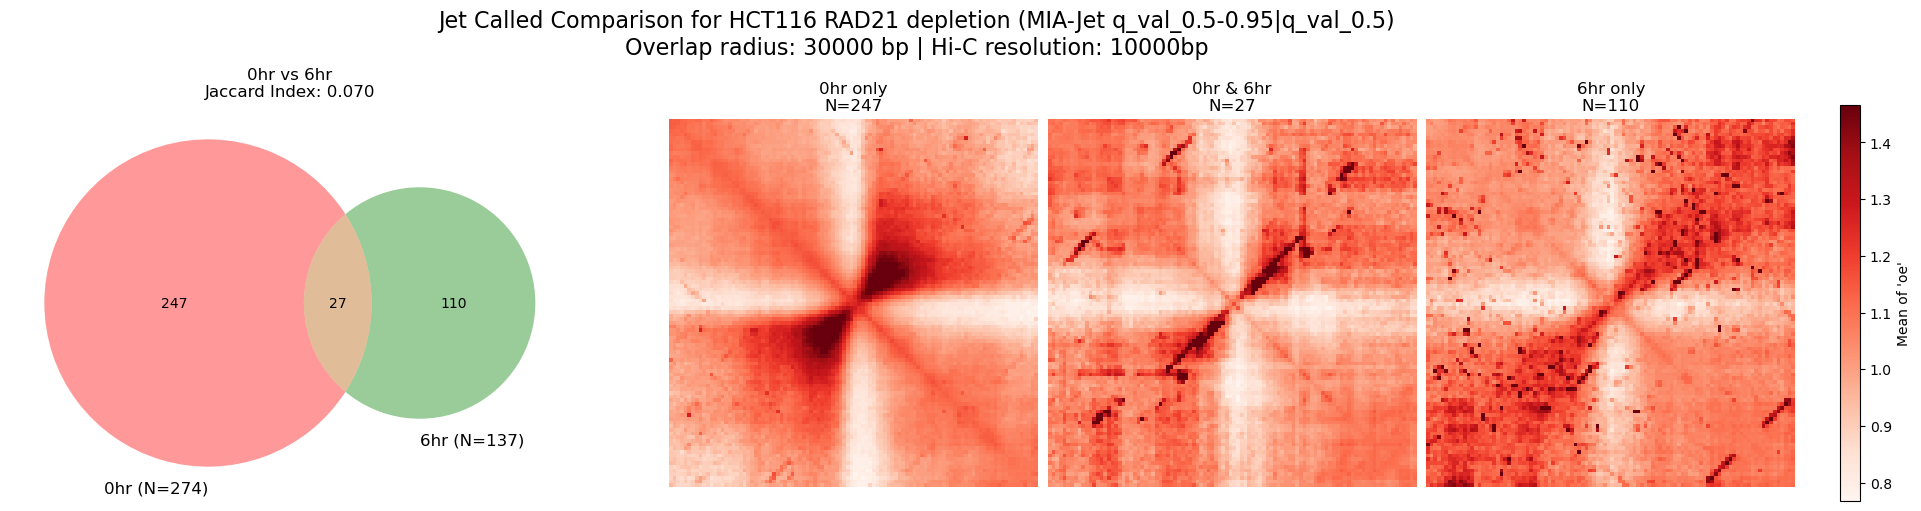

In [19]:
# PLOT VENN DIAGRAM
pairs = list(itertools.combinations(names, 2))
num_pairs = len(pairs)

fig, axes = plt.subplots(num_pairs, 4, figsize=(5*4, 5*num_pairs), layout='constrained', width_ratios=[2, 1, 1, 1])

for row, (A, B) in enumerate(pairs):
    # compute overlaps as before
    total_A = results.loc[A, A]
    total_B = results.loc[B, B]
    inter = results.loc[A, B]
    only_A = total_A - inter
    only_B = total_B - inter

    # column 0: the Venn
    ax = axes[row]
    venn2(subsets=(int(only_A), int(only_B), int(inter)),
        set_labels=(f"{A} (N={int(total_A)})", f"{B} (N={int(total_B)})"),
        ax=ax)
    ax.set_title(f"{A} vs {B}\nJaccard Index: {inter / (inter + only_A + only_B):.3f}")

    # columns 1–3: the three imshows
    # agg_map_pairs.shape == (n_pairs, 3, H, W)
    A_idx = names.index(A)
    B_idx = names.index(B)
    A_abbrev = names_abbrev[A_idx]
    B_abbrev = names_abbrev[B_idx]
    titles = [f"{A_abbrev} only", f"{A_abbrev} & {B_abbrev}", f"{B_abbrev} only"]
    counts = [int(only_A), int(inter), int(only_B)]
    row_imgs = agg_map_pairs[row]
    row_vmax = max(np.percentile(img, 99) for img in row_imgs)
    for col_idx in range(3):
        ax = axes[col_idx+1]
        img = agg_map_pairs[row, col_idx]
        im = ax.imshow(img, cmap="Reds", interpolation="none", vmax=np.percentile(img, 99))
        ax.set_title(f"{titles[col_idx]}\nN={counts[col_idx]}")
        ax.axis('off')
    fig.colorbar(im, ax=axes[1:], fraction=0.02, pad=0.04, label=f"Mean of '{data_type}'")


fig.suptitle(f"Jet Called Comparison for {data_name}\nOverlap radius: {int(buffer_radius)} bp | Hi-C resolution: {resolution}bp", fontsize=16)

# plt.savefig(f"{save_path}/{data_name}_venn_diagram-agg.png", dpi=300)

plt.show()
